In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [10]:
df = pd.read_csv(r"C:\Users\Bhamble\OneDrive\Desktop\Project\retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Number of rows and columns: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,11/24/2023,CUST001,Male,34,Beauty,3,50,150
1,2,2/27/2023,CUST002,Female,26,Clothing,2,500,1000
2,3,1/13/2023,CUST003,Male,50,Electronics,1,30,30
3,4,5/21/2023,CUST004,Male,37,Clothing,1,500,500
4,5,5/6/2023,CUST005,Male,30,Beauty,2,50,100


In [11]:
#Check the dataset
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Missing values in each column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity     

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [12]:

# Clean the data
# Create a copy so the original data remains unchanged
df_clean = df.copy()

# Convert Date into the correct date format
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Remove rows with missing values or invalid dates
df_clean = df_clean.dropna()
df_clean = df_clean.drop_duplicates()

# Check the cleaned data
print("Rows and columns after cleaning:", df_clean.shape)
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDate range:")
print("Start date:", df_clean["Date"].min())
print("End date:", df_clean["Date"].max())

display(df_clean.head())


Rows and columns after cleaning: (1000, 9)

Missing values after cleaning:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Date range:
Start date: 2023-01-01 00:00:00
End date: 2024-01-01 00:00:00


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [8]:

# Make a copy of the original dataset
df_clean = df.copy()

# Convert Date column to datetime format
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Check data types after conversion
print(df_clean.dtypes)

# Check invalid dates
print("Invalid dates:", df_clean["Date"].isna().sum())

# Check age and quantity for unusual values
print("Minimum age:", df_clean["Age"].min())
print("Maximum age:", df_clean["Age"].max())
print("Minimum quantity:", df_clean["Quantity"].min())

# Check whether total amount matches quantity × price
df_clean["Calculated Amount"] = (
    df_clean["Quantity"] * df_clean["Price per Unit"]
)

print(
    "Amount mismatches:",
    (df_clean["Total Amount"] != df_clean["Calculated Amount"]).sum()
)

# Remove the temporary validation column
df_clean.drop(columns=["Calculated Amount"], inplace=True)

print("\nData preparation completed!")


Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object
Invalid dates: 0
Minimum age: 18
Maximum age: 64
Minimum quantity: 1
Amount mismatches: 0

Data preparation completed!


In [13]:

# Calculate mean, median, mode and standard deviation
numeric_columns = [
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

print("MEAN")
display(df_clean[numeric_columns].mean())

print("\nMEDIAN")
display(df_clean[numeric_columns].median())

print("\nMODE")
display(df_clean[numeric_columns].mode().iloc[0])

print("\nSTANDARD DEVIATION")
display(df_clean[numeric_columns].std())


MEAN


Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64


MEDIAN


Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64


MODE


Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64


STANDARD DEVIATION


Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64

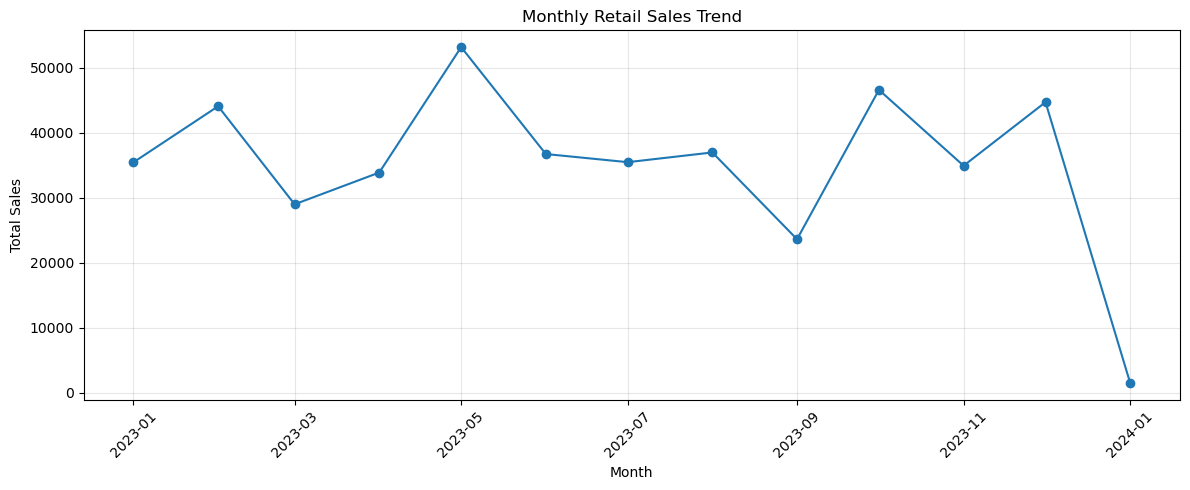

Highest sales month: May 2023
Highest monthly sales: 53150
Lowest sales month: January 2024
Lowest monthly sales: 1530


In [14]:
#Analyse monthly sales
monthly_sales = (
    df_clean
    .set_index("Date")["Total Amount"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Highest sales month:", monthly_sales.idxmax().strftime("%B %Y"))
print("Highest monthly sales:", monthly_sales.max())

print("Lowest sales month:", monthly_sales.idxmin().strftime("%B %Y"))
print("Lowest monthly sales:", monthly_sales.min())

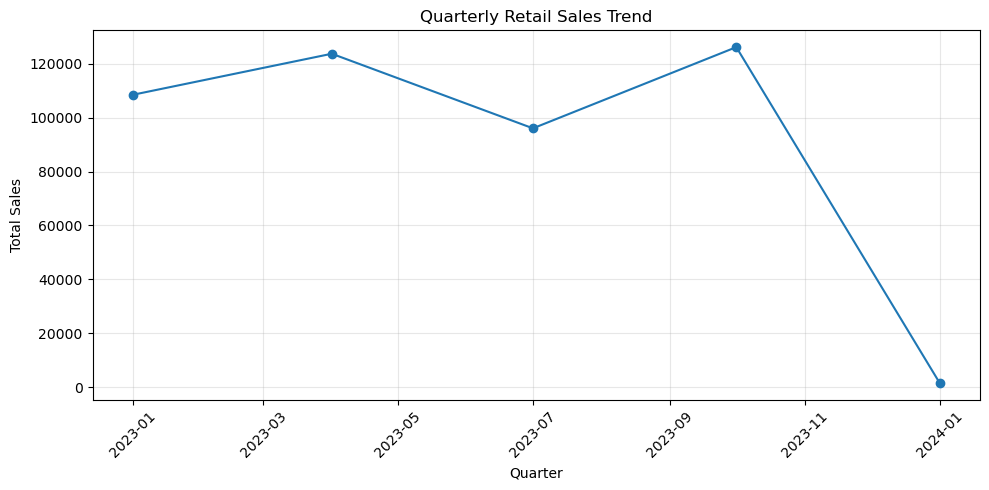

Highest sales quarter: 2023-10
Highest quarterly sales: 126190
Lowest sales quarter: 2024-01
Lowest quarterly sales: 1530


In [15]:
#Analyse quarterly sales
quarterly_sales = (
    df_clean
    .set_index("Date")["Total Amount"]
    .resample("QS")
    .sum()
)

plt.figure(figsize=(10, 5))
plt.plot(quarterly_sales.index, quarterly_sales.values, marker="o")

plt.title("Quarterly Retail Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Highest sales quarter:", quarterly_sales.idxmax().strftime("%Y-%m"))
print("Highest quarterly sales:", quarterly_sales.max())

print("Lowest sales quarter:", quarterly_sales.idxmin().strftime("%Y-%m"))
print("Lowest quarterly sales:", quarterly_sales.min())

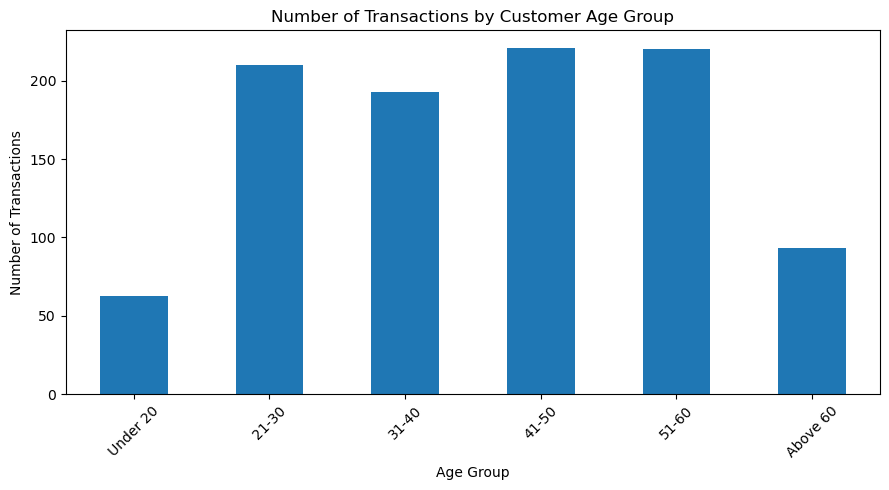

Age group with the most transactions: 41-50


Age Group
Under 20     63
21-30       210
31-40       193
41-50       221
51-60       220
Above 60     93
Name: count, dtype: int64

In [16]:
#Analyse customer age groups
df_clean["Age Group"] = pd.cut(
    df_clean["Age"],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=["Under 20", "21-30", "31-40", "41-50", "51-60", "Above 60"]
)

age_group_counts = df_clean["Age Group"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
age_group_counts.plot(kind="bar")

plt.title("Number of Transactions by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Age group with the most transactions:", age_group_counts.idxmax())
display(age_group_counts)

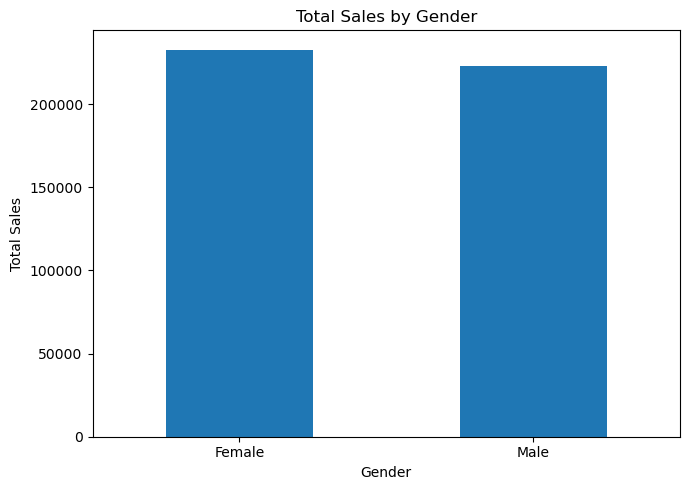

Gender with the highest total sales: Female


Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

In [17]:
#Analyse sales by gender
gender_sales = df_clean.groupby("Gender")["Total Amount"].sum()

plt.figure(figsize=(7, 5))
gender_sales.plot(kind="bar")

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Gender with the highest total sales:", gender_sales.idxmax())
display(gender_sales)

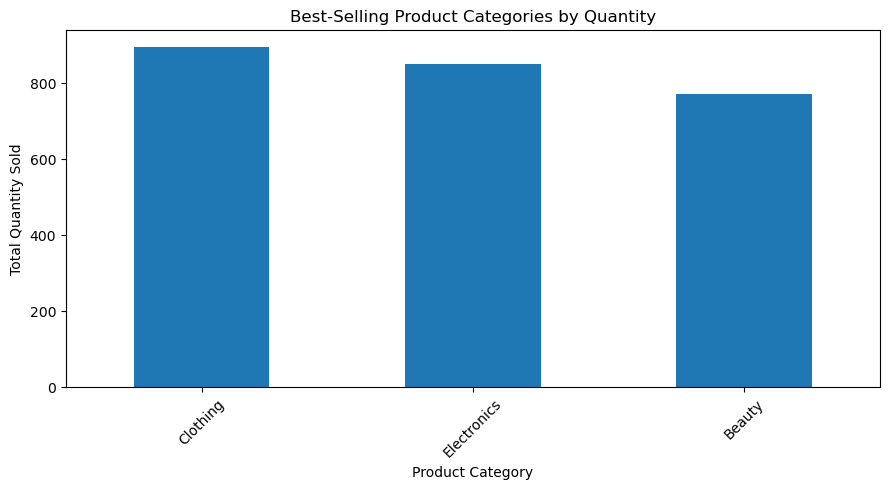

Categories ranked by quantity sold:


Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

In [18]:
#Find the best-selling categories
category_quantity = (
    df_clean.groupby("Product Category")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

top_categories = category_quantity.head(10)

plt.figure(figsize=(9, 5))
top_categories.plot(kind="bar")

plt.title("Best-Selling Product Categories by Quantity")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Categories ranked by quantity sold:")
display(top_categories)

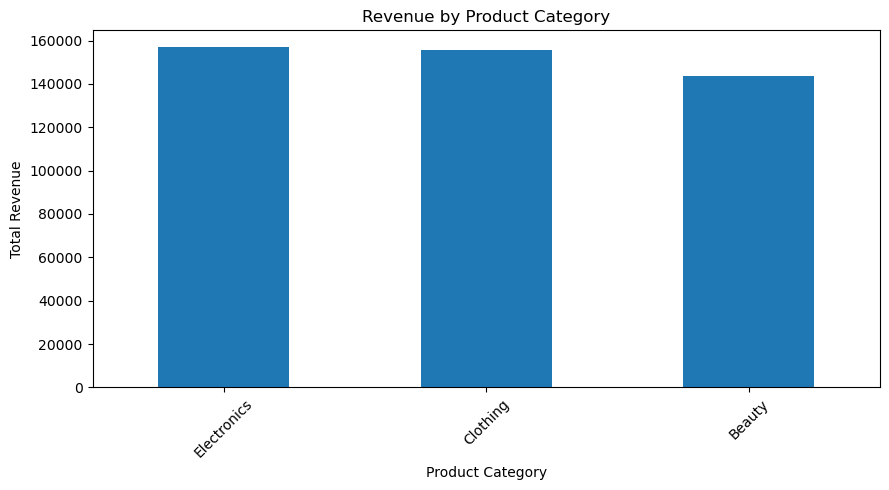

Categories ranked by revenue:


Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

In [19]:
#Calculate revenue by product category
category_revenue = (
    df_clean.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
category_revenue.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Categories ranked by revenue:")
display(category_revenue)

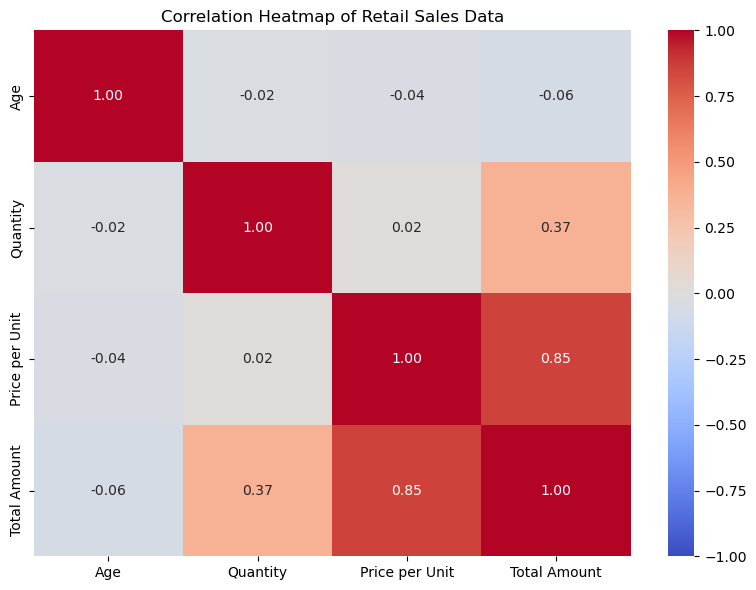

In [20]:
#Create a correlation heatmap
numeric_data = df_clean[
    ["Age", "Quantity", "Price per Unit", "Total Amount"]
]

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Retail Sales Data")
plt.tight_layout()
plt.show()

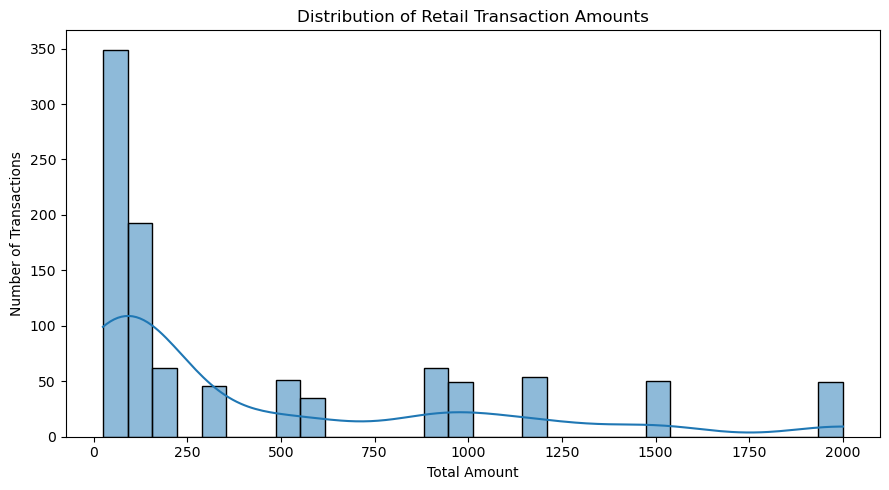

In [21]:
#Create one additional chart
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="Total Amount",
    bins=30,
    kde=True
)

plt.title("Distribution of Retail Transaction Amounts")
plt.xlabel("Total Amount")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

In [22]:
#Print a final summary
print("========== RETAIL SALES SUMMARY ==========")

print("Total transactions:", len(df_clean))
print("Total revenue:", df_clean["Total Amount"].sum())
print("Average transaction amount:", round(df_clean["Total Amount"].mean(), 2))
print("Average customer age:", round(df_clean["Age"].mean(), 2))

print(
    "Top revenue category:",
    df_clean.groupby("Product Category")["Total Amount"].sum().idxmax()
)

print(
    "Most common gender:",
    df_clean["Gender"].mode()[0]
)

print(
    "Most common age group:",
    df_clean["Age Group"].mode()[0]
)

print("==========================================")

========== RETAIL SALES SUMMARY ==========
Total transactions: 1000
Total revenue: 456000
Average transaction amount: 456.0
Average customer age: 41.39
Top revenue category: Electronics
Most common gender: Female
Most common age group: 41-50


In [ ]:
# Conclusion

In this project, Exploratory Data Analysis (EDA) was performed on retail sales data using Python, pandas, Matplotlib and Seaborn. The dataset was inspected and cleaned, and descriptive statistics were calculated to understand customer demographics, quantities purchased, product prices and transaction amounts.

Monthly and quarterly sales trends were analysed to understand changes in sales over time. Customer age groups and gender were examined, and product categories were compared by quantity sold and revenue generated. A correlation heatmap and transaction amount distribution chart were also created to explore relationships between numerical variables and purchasing patterns.

## Business Recommendations

1. **Improve inventory planning:** Maintain sufficient stock of categories with high sales quantities to reduce the risk of stockouts.
2. **Plan promotions strategically:** Use monthly and quarterly sales patterns to plan marketing campaigns during weaker sales periods.
3. **Use sales data for decision-making:** Compare category revenue and customer purchasing patterns when planning product promotions and business strategies.

Overall, this project demonstrates how EDA can help businesses understand retail sales patterns and make data-informed decisions.